# Real Estate Analysis

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import calendar

In [2]:
BASE_DIR = Path().resolve().parents[0]
file_path = BASE_DIR / "data/clean/dvf_clean.parquet"

In [3]:
df = pd.read_parquet(file_path)

In [4]:
df.shape

(805167, 18)

In [5]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 805167 entries, 0 to 805166
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Date mutation              805167 non-null  datetime64[us]
 1   Nature mutation            805167 non-null  category      
 2   Valeur fonciere            805167 non-null  float64       
 3   No voie                    801970 non-null  float64       
 4   Type de voie               805167 non-null  string        
 5   Code voie                  805167 non-null  string        
 6   Voie                       805167 non-null  string        
 7   Code postal                805167 non-null  string        
 8   Commune                    805167 non-null  category      
 9   Code departement           805167 non-null  string        
 10  Code commune               805167 non-null  int64         
 11  Section                    805167 non-null  string        
 12 

In [6]:
df.head()

,Date mutation,Nature mutation,Valeur fonciere,No voie,Type de voie,Code voie,Voie,Code postal,Commune,Code departement,Code commune,Section,No plan,Code type local,Type local,Surface reelle bati,Nombre pieces principales,prix_m2
0,2025-01-07,Vente,468000.0,454.0,RUE,0090,DE LA REPUBLIQUE,1550,FARGES,01,158,B,910,1.0,Maison,111.0,5.0,4216.216216
1,2025-01-06,Vente,180000.0,66.0,RUE,0050,DE LA FRUITIERE,1200,MONTANGES,01,257,AC,341,2.0,Appartement,87.0,4.0,2068.965517
2,2025-01-06,Vente,490000.0,459.0,CHE,0356,DU PETIT CORGENON,1310,BUELLAS,01,65,B,1705,1.0,Maison,190.0,6.0,2578.947368
3,2025-01-09,Vente,183000.0,250.0,AV,0041,DE BELLE FERME,1170,GEX,01,173,AH,194,2.0,Appartement,35.0,2.0,5228.571429
4,2025-01-07,Vente,295000.0,129.0,RTE,0800,DE LA FRAZE,1990,BANEINS,01,28,C,162,1.0,Maison,95.0,2.0,3105.263158


### Overall analysis of the "`prix_m2`"

In [7]:
df["prix_m2"].describe()

count    8.051670e+05
mean     3.235467e+03
std      5.185656e+03
min      1.379310e-03
25%      1.677966e+03
50%      2.575373e+03
75%      3.898305e+03
max      2.546587e+06
Name: prix_m2, dtype: float64

- Right-skewed distribution with a heavy tail
    - Some very high values pull the average upwards
- Median represents the real market
- Average is skewed by premium zones ("`prix_m2`" by city)

#### Distribution of "`prix_m2`"

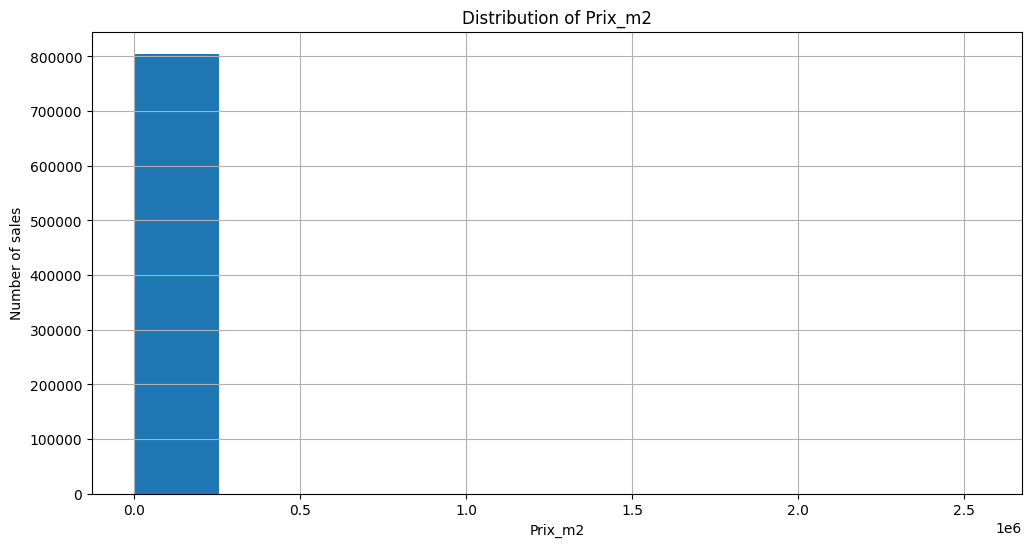

In [8]:
plt.figure(figsize=(12, 6))

df["prix_m2"].hist(bins=10)

plt.title("Distribution of Prix_m2")
plt.xlabel("Prix_m2")
plt.ylabel("Number of sales")

plt.show()

##### Distribution (heavy tail)

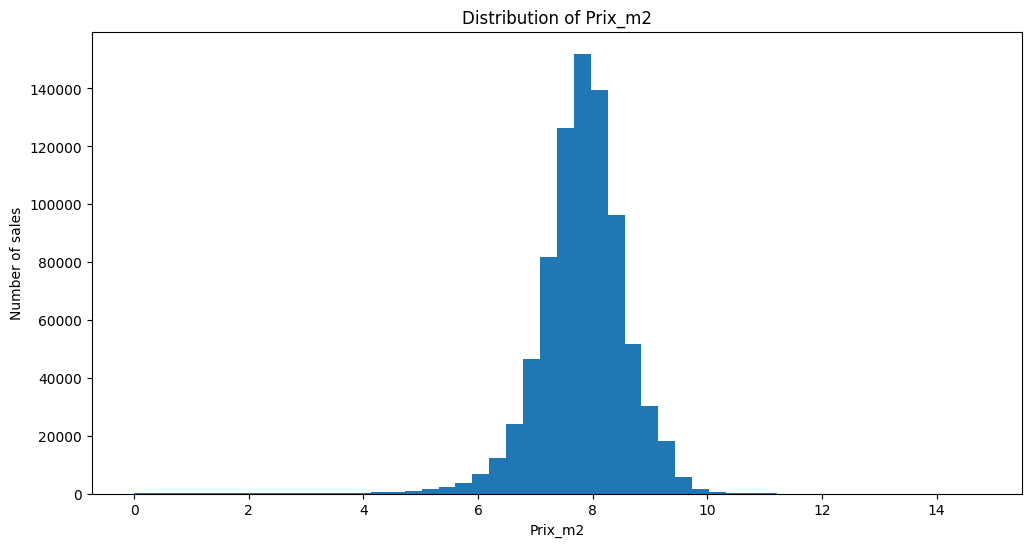

In [9]:
plt.figure(figsize=(12, 6))

plt.hist(np.log1p(df["prix_m2"]), bins=50)

plt.title("Distribution of Prix_m2")
plt.xlabel("Prix_m2")
plt.ylabel("Number of sales")

plt.show()

 #### Boxplot of "`prix_m2`"

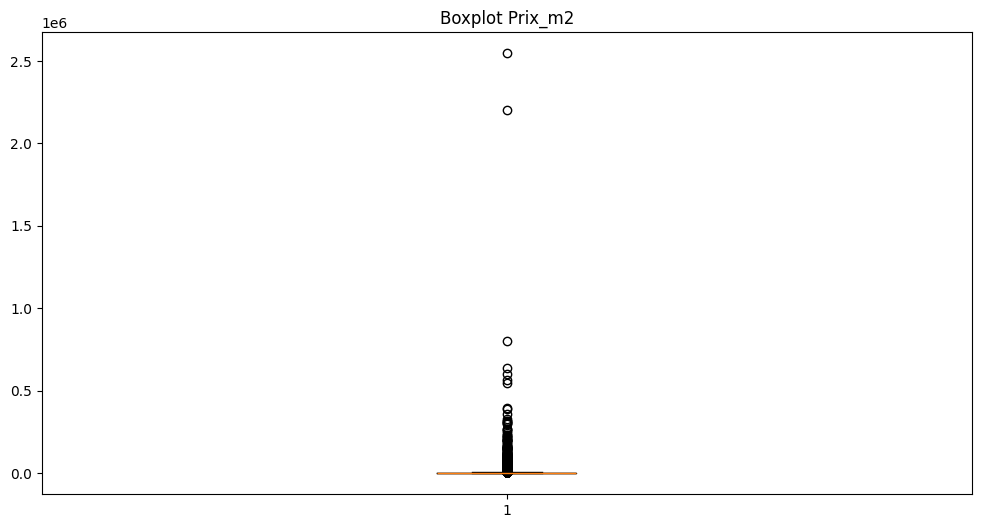

In [10]:
plt.figure(figsize=(12, 6))
plt.boxplot(df["prix_m2"])
plt.title("Boxplot Prix_m2")
plt.show()

### "`prix_m2`" by property type

In [11]:
df.groupby("Type local")["prix_m2"].describe()

,count,mean,std,min,25%,50%,75%,max
Type local,,,,,,,,
Appartement,348593.0,4113.316332,4336.885014,0.004219,2200.000000,3317.460317,4997.753333,8.000000e+05
Maison,456574.0,2565.230594,5659.013296,0.001379,1428.571429,2156.862745,3119.635989,2.546587e+06


- Market dominated by apartments (Appartement > Local > Maison)
- Very heterogeneous market (premium and rural areas, expensive cities)
- Commercial premises dominate in average value but are very unstable.
- Houses and apartments are close in median price: homogeneous residential market.
- High presence of outliers: the average is not reliable.

Commercial properties (`Local industriel. commercial ou assimilé`) are heterogeneous assets and may not be directly comparable to residential properties.

In [12]:
median_by_type = (
    df.groupby("Type local")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

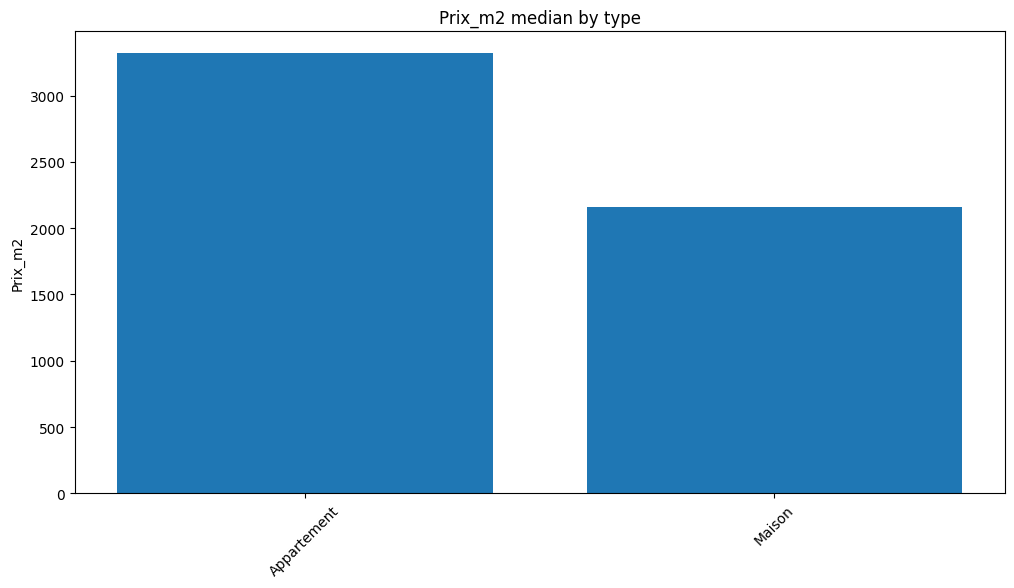

In [13]:
plt.figure(figsize=(12, 6))

plt.bar(
    median_by_type.index,
    median_by_type.values
)

plt.title("Prix_m2 median by type")
plt.ylabel("Prix_m2")
plt.xticks(rotation=45)
plt.show()

### Prix_m2 by city

In [14]:
df["Commune"] = df["Commune"].cat.remove_unused_categories()

In [15]:
city_counts = df["Commune"].value_counts()
print(len(city_counts))

28773


In [16]:
treshold_city_count = city_counts.quantile(0.99)
valid_cities = city_counts[city_counts >= treshold_city_count].index

df_city = df[df["Commune"].isin(valid_cities)]
print(len(valid_cities))

289


In [17]:
city_prices = (
    df_city.groupby("Commune")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

city_prices.sort_values(ascending=False).head(20)

Commune
PARIS 06             14103.913630
PARIS 07             13888.888889
PARIS 04             12706.919946
PARIS 08             12044.776119
PARIS 03             11833.333333
PARIS 05             11708.399916
PARIS 16             10873.287065
PARIS 09             10797.002315
NEUILLY-SUR-SEINE    10441.954023
PARIS 17             10000.000000
PARIS 11              9901.410256
PARIS 15              9473.684211
PARIS 14              9430.522799
PARIS 10              9260.033333
LEVALLOIS-PERRET      9036.363636
PARIS 12              9000.000000
PARIS 18              8846.153846
VINCENNES             8653.333333
PARIS 13              8620.338462
PARIS 20              8351.732014
Name: prix_m2, dtype: float64

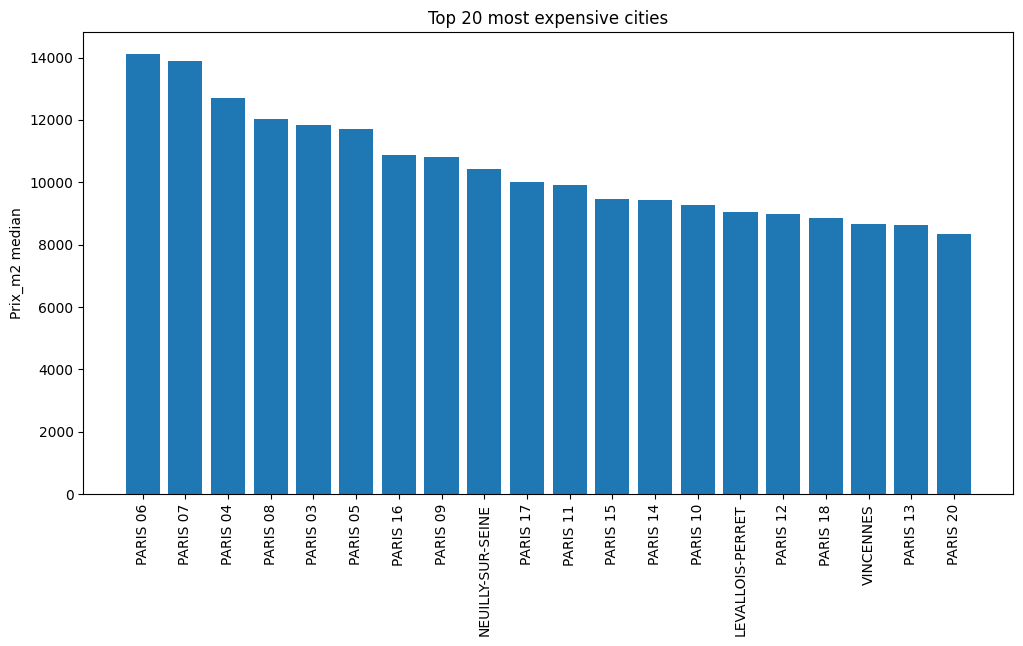

In [18]:
top_cities = city_prices.head(20)

plt.figure(figsize=(12, 6))

plt.bar(top_cities.index, top_cities.values)

plt.xticks(rotation=90)
plt.ylabel("Prix_m2 median")
plt.title("Top 20 most expensive cities")

plt.show()

##### Geographical bias
The dataset may:
- overrepresent some major cities
- under-represent certain rural areas

### Prix_m2 by `departement`

In [19]:
dept_counts = df["Code departement"].value_counts()

In [20]:
treshold_dept_count = dept_counts.quantile(0.9)
valid_dept = dept_counts[dept_counts >= treshold_dept_count].index

df_dept = df[df["Code departement"].isin(valid_dept)]
print(len(valid_dept))

10


In [21]:
dept_prices = (
    df_dept.groupby("Code departement")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

dept_prices.sort_values(ascending=False).head(20)

Code departement
75    9694.117647
06    4931.506849
83    3979.591837
69    3693.085106
13    3600.000000
33    3370.967742
34    3244.812500
44    3043.000000
31    2826.086957
59    2081.864973
Name: prix_m2, dtype: float64

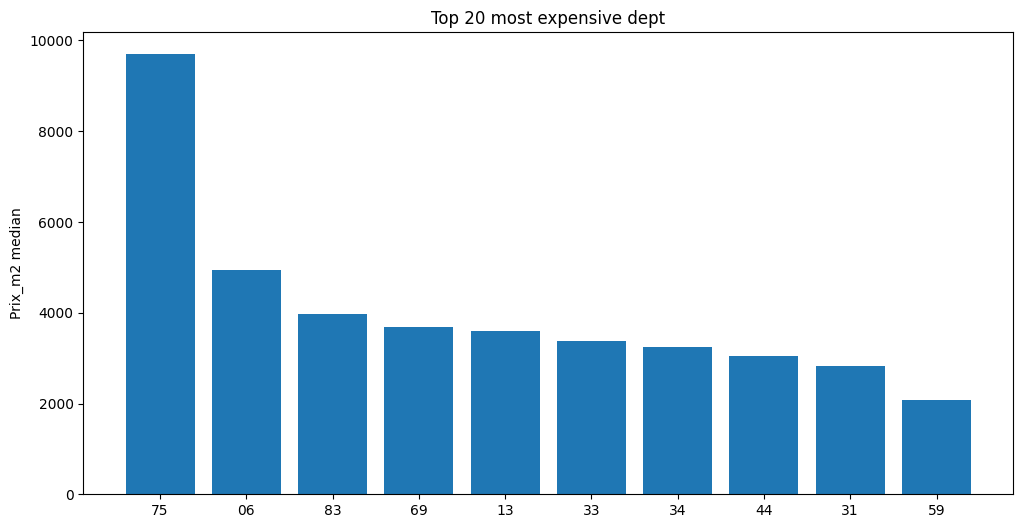

In [22]:
top_dept = dept_prices.head(20)

plt.figure(figsize=(12, 6))

plt.bar(top_dept.index, top_dept.values)

plt.ylabel("Prix_m2 median")
plt.title("Top 20 most expensive dept")

plt.show()

### Temporal analysis

In [23]:
monthly_transactions = (
    df["Date mutation"]
    .dt.month
    .value_counts()
    .sort_index()
)
print(monthly_transactions)

Date mutation
1     56051
2     55794
3     69742
4     67647
5     53516
6     73069
7     89627
8     56476
9     77348
10    73700
11    57506
12    74691
Name: count, dtype: int64


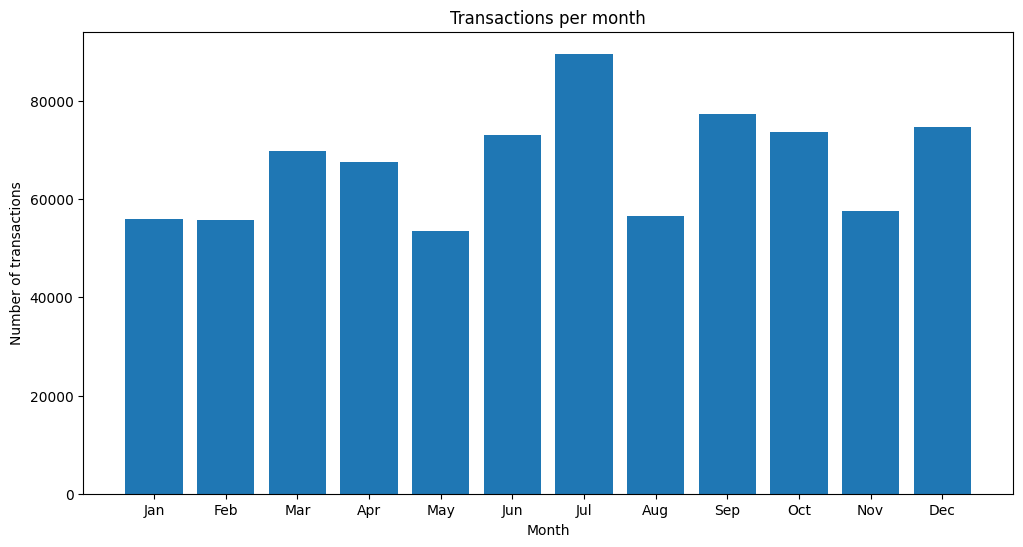

In [24]:
months = range(1, 13)
month_names = [calendar.month_abbr[m] for m in months]

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_transactions.index,
    monthly_transactions.values
)

plt.title("Transactions per month")
plt.xlabel("Month")
plt.xticks(months, month_names)
plt.ylabel("Number of transactions")

plt.show()

- Volumes vary greatly: up to 67% difference between months
- Low activity on May, February and January
- High activity on July, September and December
- **Seasonality** which can be explain by families buying before the start of the school year and house moving in summer

In [25]:
monthly_prices = (
    df.groupby(df["Date mutation"].dt.month)["prix_m2"]
    .median()
)
print(monthly_prices)

Date mutation
1     2555.555556
2     2535.168659
3     2606.847375
4     2500.000000
5     2517.157275
6     2619.047619
7     2629.629630
8     2543.774485
9     2651.515152
10    2591.400183
11    2531.250000
12    2567.893443
Name: prix_m2, dtype: float64


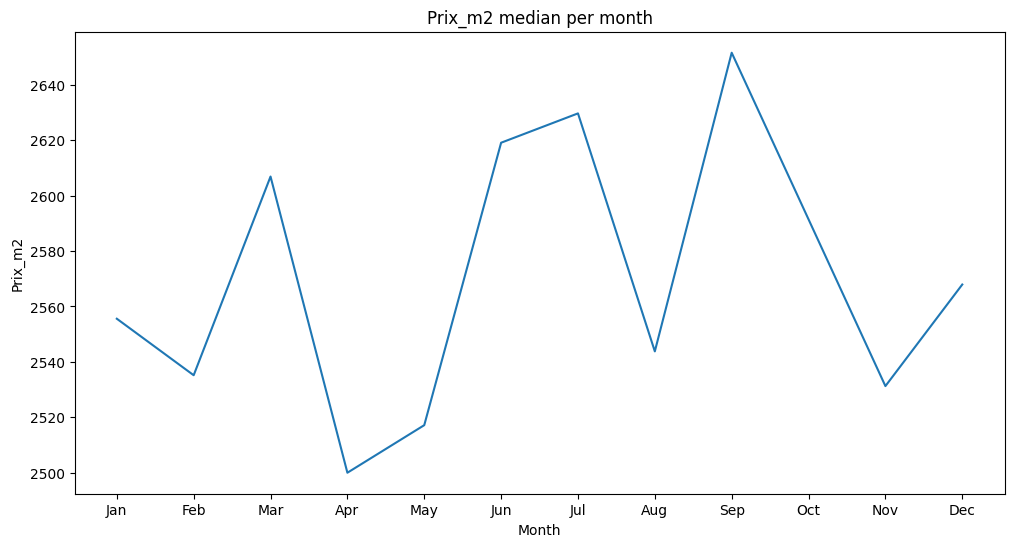

In [26]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_prices.index,
    monthly_prices.values
)

plt.title("Prix_m2 median per month")
plt.xlabel("Month")
plt.xticks(months, month_names)
plt.ylabel("Prix_m2")

plt.show()

- No strong seasonality
    - Months slightly more expensive : December, September, July and March
    - Months slightly cheaper : April, August and February

The price/m² (`prix_m2`) remains generally stable throughout the year, with limited variations (~6% on the monthly median). This suggests a lack of strong seasonality in real estate prices, contrary to the transaction volume, which is highly seasonal.

### `Surface reelle bati` analysis

In [27]:
df["Surface reelle bati"].describe()

count    805167.000000
mean         82.311866
std          42.431224
min           1.000000
25%          54.000000
50%          77.000000
75%         102.000000
max        1537.000000
Name: Surface reelle bati, dtype: float64

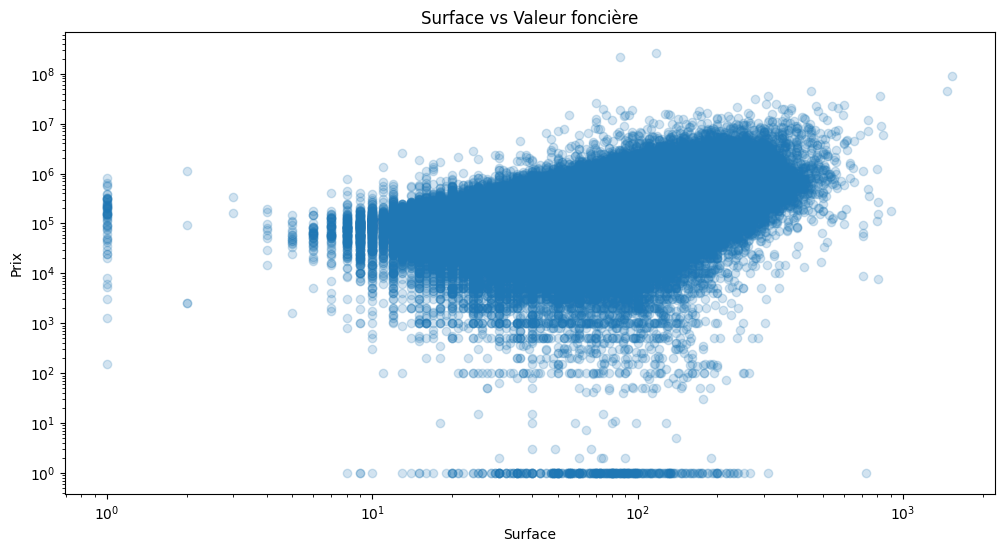

In [28]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df["Surface reelle bati"],
    df["Valeur fonciere"],
    alpha=0.2
)

plt.title("Surface vs Valeur foncière")
plt.xlabel("Surface")
plt.ylabel("Prix")

plt.xscale("log")
plt.yscale("log")

plt.show()

### Correlations

In [29]:
numeric_cols = df[["Valeur fonciere", "Surface reelle bati", "Nombre pieces principales", "prix_m2"]]

print(numeric_cols.corr(method="spearman"))

                           Valeur fonciere  Surface reelle bati  \
Valeur fonciere                   1.000000             0.440903   
Surface reelle bati               0.440903             1.000000   
Nombre pieces principales         0.390572             0.851230   
prix_m2                           0.675929            -0.284802   

                           Nombre pieces principales   prix_m2  
Valeur fonciere                             0.390572  0.675929  
Surface reelle bati                         0.851230 -0.284802  
Nombre pieces principales                   1.000000 -0.245195  
prix_m2                                    -0.245195  1.000000  


- 1st factor : price/m² (`prix_m2`)
- 2nd factor : `Surface reelle bati`
- 3rd factor : number of rooms (`Nombre pieces principales`)

Real estate value is mainly correlated with the price/m², while area plays a secondary role. The number of rooms explains very little in price variations, which highlights the importance of the location and positioning of the property in the real estate market.

### Top transactions

In [30]:
df.sort_values(
    by="Valeur fonciere",
    ascending=False
)[[
    "Commune",
    "Type local",
    "Valeur fonciere",
    "Surface reelle bati",
    "prix_m2"
]].head(20)

,Commune,Type local,Valeur fonciere,Surface reelle bati,prix_m2
543716,SAINT-LOUP-DE-VARENNES,Maison,257500000.0,117.0,2.200855e+06
514311,NEFIACH,Maison,219006504.0,86.0,2.546587e+06
558741,COURCHEVEL,Maison,89100000.0,1537.0,5.797007e+04
28025,ROQUEBRUNE CAP MARTIN,Maison,44500000.0,450.0,9.888889e+04
796383,PARIS 16,Appartement,44000000.0,1469.0,2.995235e+04
642431,SAINT TROPEZ,Maison,36000000.0,311.0,1.157556e+05
641649,SAINT TROPEZ,Maison,36000000.0,822.0,4.379562e+04
801988,PARIS 07,Maison,31500000.0,277.0,1.137184e+05
589621,TANCARVILLE,Maison,25301100.0,70.0,3.614443e+05
649783,SAINT TROPEZ,Maison,25000000.0,334.0,7.485030e+04


### Detection of atypical real estate

#### Very expensive `prix_m2`

In [31]:
top_quantile = df["prix_m2"].quantile(0.9)

In [32]:
df[df["prix_m2"] > top_quantile][[
    "Commune",
    "Type local",
    "Valeur fonciere",
    "Surface reelle bati",
    "prix_m2"
]].head(20)

,Commune,Type local,Valeur fonciere,Surface reelle bati,prix_m2
8,THOIRY,Maison,1165000.0,190.0,6131.578947
9,POUGNY,Maison,630000.0,100.0,6300.000000
11,CHALLEX,Appartement,414665.0,67.0,6189.029851
23,DIVONNE-LES-BAINS,Appartement,475000.0,67.0,7089.552239
44,CESSY,Maison,1200670.0,199.0,6033.517588
98,CESSY,Maison,659630.0,105.0,6282.190476
131,PREVESSIN-MOENS,Appartement,292100.0,40.0,7302.500000
158,GEX,Maison,600000.0,98.0,6122.448980
203,TREVOUX,Maison,412000.0,65.0,6338.461538
222,DIVONNE-LES-BAINS,Appartement,650000.0,102.0,6372.549020


#### Very low `prix_m2`

In [33]:
bottom_quantile = df["prix_m2"].quantile(q=0.1)

In [34]:
df[df["prix_m2"] < bottom_quantile][[
    "Commune",
    "Type local",
    "Valeur fonciere",
    "Surface reelle bati",
    "prix_m2"
]].head(20)

,Commune,Type local,Valeur fonciere,Surface reelle bati,prix_m2
51,AMBERIEUX-EN-DOMBES,Maison,100000.0,96.0,1041.666667
81,VONNAS,Appartement,47000.0,139.0,338.129496
90,BRENOD,Maison,113000.0,108.0,1046.296296
94,FOISSIAT,Maison,175000.0,170.0,1029.411765
128,SAINT-DIDIER-SUR-CHALARONNE,Appartement,45000.0,48.0,937.500000
134,NANTUA,Maison,113000.0,128.0,882.812500
144,SIMANDRE-SUR-SURAN,Maison,13500.0,30.0,450.000000
190,SAINT-RAMBERT-EN-BUGEY,Maison,60000.0,80.0,750.000000
193,VAUX-EN-BUGEY,Maison,27600.0,53.0,520.754717
205,MONTLUEL,Maison,75000.0,100.0,750.000000


## Core market

In [35]:
q10 = df["prix_m2"].quantile(0.1)
q90 = df["prix_m2"].quantile(0.9)

df_core = df[
    (df["prix_m2"] >= q10) &
    (df["prix_m2"] <= q90)
]

### New overall analysis of the "`prix_m2`"

In [36]:
print(df_core["prix_m2"].describe())

count    644137.000000
mean       2792.656699
std        1170.934105
min        1063.636364
25%        1853.225806
50%        2575.342466
75%        3548.387097
max        5925.925926
Name: prix_m2, dtype: float64


- The distribution remains asymmetrical on the right
- Median represents the real market

**Before and after 'Core market'**
||Before|After|
|---|:-:|:-:|
|**Mean**|6840|3919|
|**Std**|18489|1924|
|**Max**|324871|9800|

After removing extreme outliers, the price-per-square-meter (`price_m2`) distribution becomes significantly more stable and representative of the standard residential real estate market. The mean and median are now much closer, indicating a substantial reduction in skewness caused by luxury or anomalous transactions.

#### Distribution of "`prix_m2`"

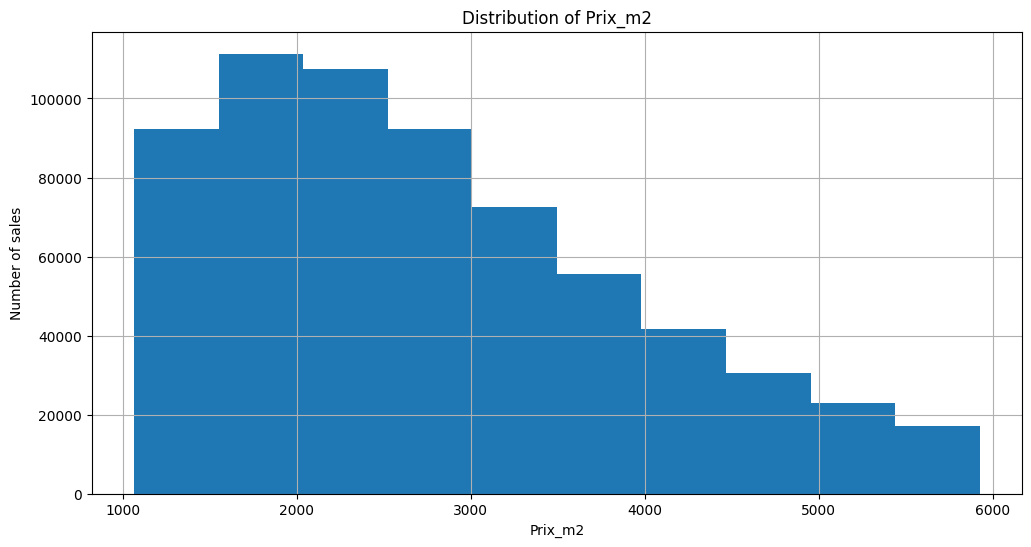

In [37]:
plt.figure(figsize=(12, 6))

df_core["prix_m2"].hist(bins=10)

plt.title("Distribution of Prix_m2")
plt.xlabel("Prix_m2")
plt.ylabel("Number of sales")

plt.show()

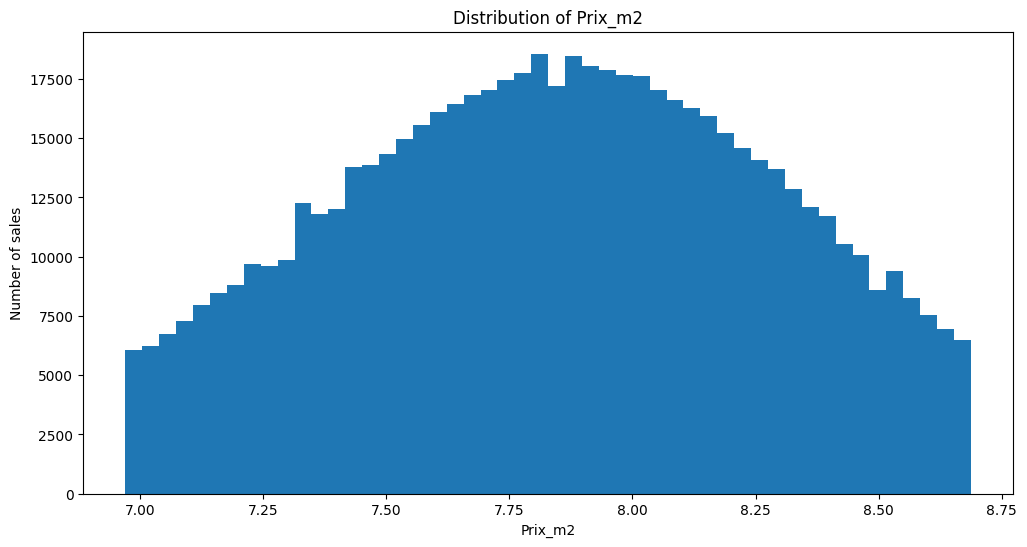

In [38]:
plt.figure(figsize=(12, 6))

plt.hist(np.log1p(df_core["prix_m2"]), bins=50)

plt.title("Distribution of Prix_m2")
plt.xlabel("Prix_m2")
plt.ylabel("Number of sales")

plt.show()

#### Boxplot of "`prix_m2`"

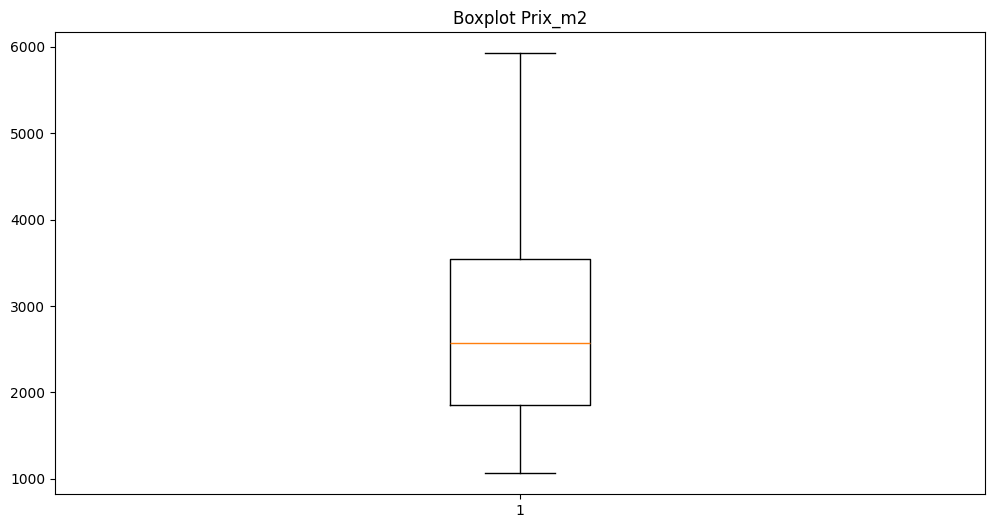

In [39]:
plt.figure(figsize=(12, 6))

plt.boxplot(df_core["prix_m2"])

plt.title("Boxplot Prix_m2")

plt.show()

### "`prix_m2`" by property type

In [40]:
print(df_core.groupby("Type local")["prix_m2"].describe())

                count         mean          std          min          25%  \
Type local                                                                  
Appartement  270938.0  3136.689333  1217.815761  1063.636364  2153.846154   
Maison       373199.0  2542.893130  1068.400222  1063.636364  1712.500000   

                     50%          75%          max  
Type local                                          
Appartement  3000.000000  4015.151515  5925.925926  
Maison       2315.416542  3146.067416  5925.925926  


- Apartments remain the most expensive
- Houses are cheaper per square meter

After removing extreme outliers, `prix_m2` differences between property types become much smaller. Apartments remain the most expensive segment on average, while houses are slightly cheaper per m². Commercial properties no longer dominate artificially, confirming that previous analyses were heavily skewed by extreme transactions.

Reminder : Commercial properties (`Local industriel. commercial ou assimilé`) are heterogeneous assets and may not be directly comparable to residential properties.

In [41]:
median_by_type = (
    df_core.groupby("Type local")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

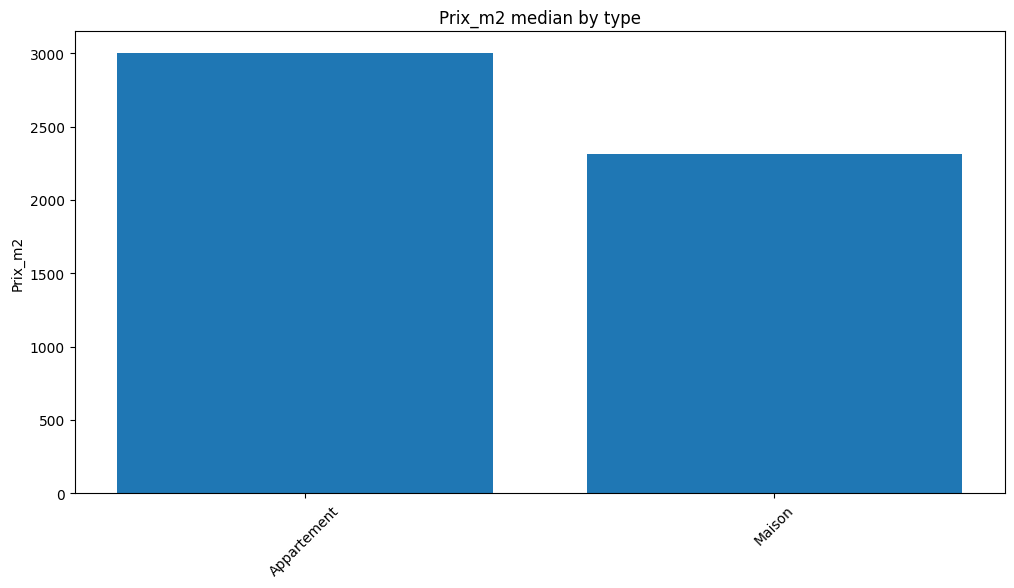

In [42]:
plt.figure(figsize=(12, 6))

plt.bar(
    median_by_type.index,
    median_by_type.values
)

plt.title("Prix_m2 median by type")
plt.ylabel("Prix_m2")
plt.xticks(rotation=45)
plt.show()

### Top city (volume)

In [43]:
top_city = df_core["Commune"].value_counts().head(10)
print(top_city)

Commune
TOULOUSE       7115
NICE           4729
NANTES         4446
MONTPELLIER    4140
BORDEAUX       3800
LILLE          3162
RENNES         3000
TOULON         2729
DIJON          2713
BREST          2384
Name: count, dtype: int64


In [44]:
df_core_top_city = df_core[df_core["Commune"].isin(top_city.index)]

top_city_prices = (
    df_core_top_city.groupby("Commune")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

top_city_prices.sort_values(ascending=False).head(20)

Commune
NICE           4306.644737
BORDEAUX       4117.647059
RENNES         3732.646048
NANTES         3467.815922
LILLE          3452.380952
MONTPELLIER    3440.588235
TOULOUSE       3283.582090
TOULON         2857.142857
DIJON          2767.961165
BREST          2241.801075
Name: prix_m2, dtype: float64

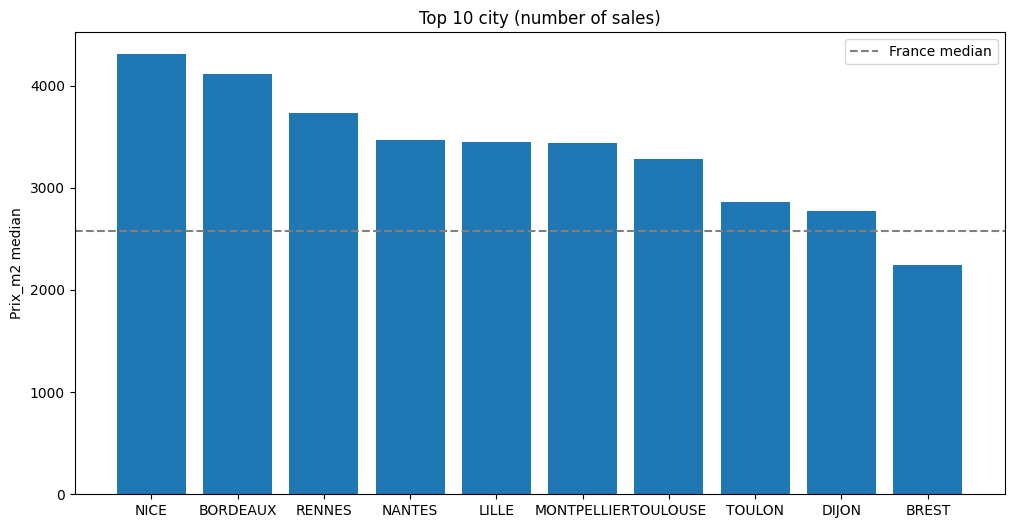

In [45]:
plt.figure(figsize=(12, 6))

plt.bar(top_city_prices.index, top_city_prices.values)

plt.axhline(df_core["prix_m2"].median(), label="France median" ,color="grey", linestyle="dashed")

plt.ylabel("Prix_m2 median")
plt.title("Top 10 city (number of sales)")

plt.legend(loc="upper right")

plt.show()

### Prix_m2 by city

In [46]:
city_counts = df_core["Commune"].value_counts()
print(len(city_counts))

28773


In [47]:
treshold_city_count = city_counts.quantile(0.9)
valid_cities = city_counts[city_counts >= treshold_city_count].index

df_core_city = df_core[df_core["Commune"].isin(valid_cities)]
print(len(valid_cities))

2925


In [48]:
city_prices = (
    df_core_city.groupby("Commune")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

print(city_prices.sort_values(ascending=False).head(20))

Commune
SAINT-CLOUD             5356.164384
CHARENTON-LE-PONT       5343.879121
PUTEAUX                 5287.671233
SAINT-OUEN-SUR-SEINE    5250.000000
BUC                     5245.932540
ORNEX                   5232.394366
COURBEVOIE              5231.818182
MONTROUGE               5219.371429
LES LILAS               5211.267606
MALAKOFF                5210.526316
MORZINE                 5192.378838
BOIS-COLOMBES           5192.307692
ASNIERES-SUR-SEINE      5191.085823
GENTILLY                5188.679245
LE PRE-SAINT-GERVAIS    5185.714286
SURESNES                5172.413793
LE PLESSIS-ROBINSON     5169.409283
CAPBRETON               5167.924528
LA CROIX VALMER         5166.977612
LA GARENNE-COLOMBES     5166.666667
Name: prix_m2, dtype: float64


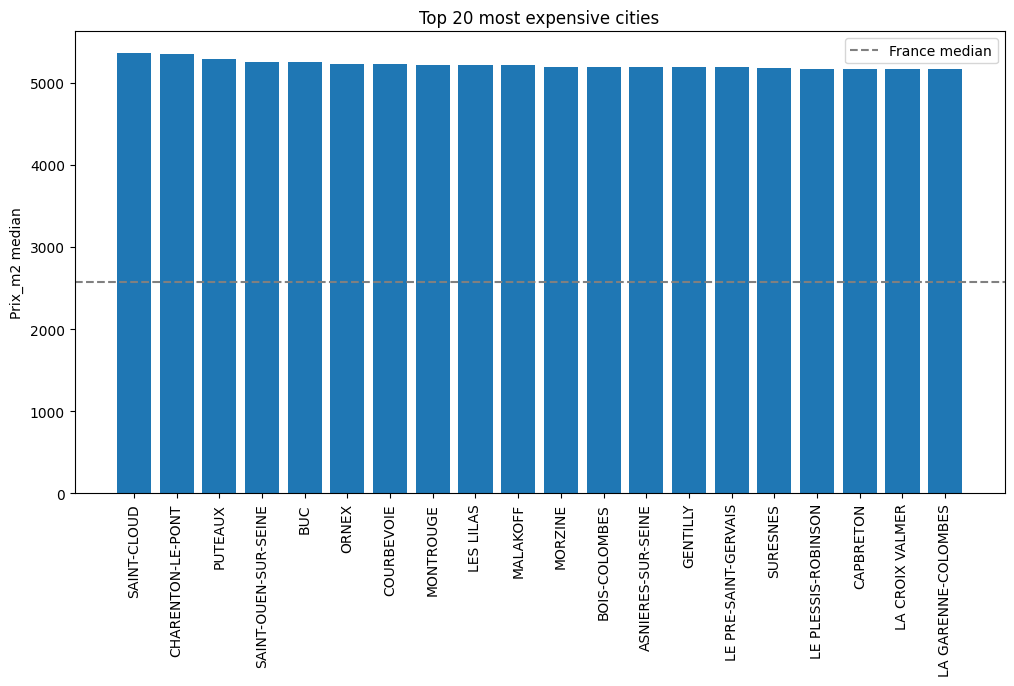

In [49]:
top_cities = city_prices.sort_values(ascending=False).head(20)

plt.figure(figsize=(12, 6))

plt.bar(top_cities.index, top_cities.values)
plt.axhline(df_core["prix_m2"].median(), label="France median" ,color="grey", linestyle="dashed")

plt.xticks(rotation=90)
plt.ylabel("Prix_m2 median")
plt.title("Top 20 most expensive cities")

plt.legend(loc="upper right")

plt.show()

### Prix_m2 by `departement`

In [50]:
core_dept_counts = df_core["Code departement"].value_counts()

In [51]:
treshold_core_dept_count = core_dept_counts.quantile(0.9)
valid_dept = core_dept_counts[core_dept_counts >= treshold_core_dept_count].index

df_core_dept = df_core[df_core["Code departement"].isin(valid_dept)]
print(len(valid_dept))

10


In [52]:
core_dept_prices = (
    df_core_dept.groupby("Code departement")["prix_m2"]
    .median()
    .sort_values(ascending=False)
)

core_dept_prices.sort_values(ascending=False).head(20)

Code departement
06    4285.714286
69    3622.005416
83    3573.095801
13    3437.500000
33    3301.587302
34    3246.709957
77    3043.478261
44    3018.442833
31    2847.457627
59    2250.000000
Name: prix_m2, dtype: float64

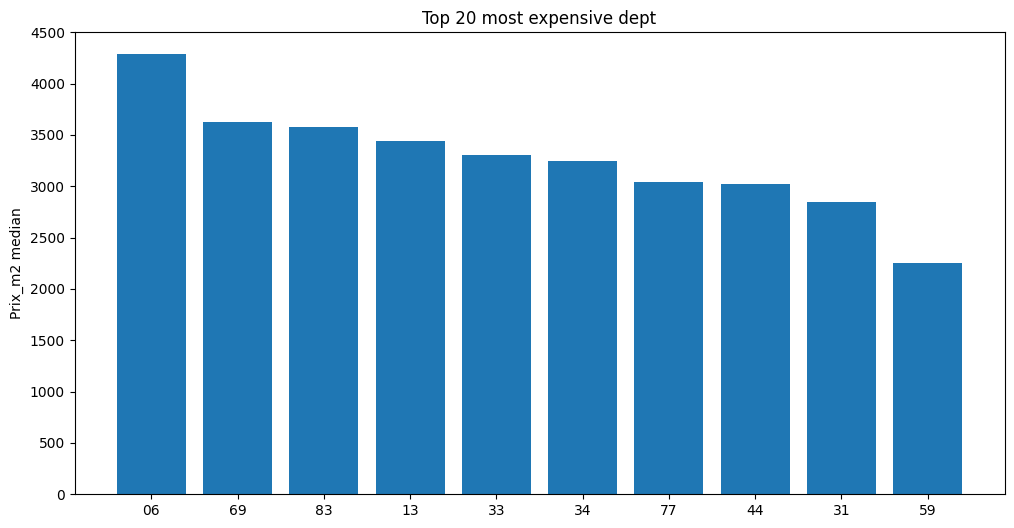

In [53]:
core_top_dept = core_dept_prices.head(20)

plt.figure(figsize=(12, 6))

plt.bar(core_top_dept.index, core_top_dept.values)

plt.ylabel("Prix_m2 median")
plt.title("Top 20 most expensive dept")

plt.show()

### Prix_m2 by `departement` and `type local`

In [54]:
df_core_dept_type = df_core.groupby(
    ["Code departement", "Type local"]
)["prix_m2"].median()
df_core_dept_type

Code departement  Type local 
01                Appartement    2650.757576
                  Maison         2554.411765
02                Appartement    1505.309903
                  Maison         1581.196581
03                Appartement    1696.040373
                                    ...     
972               Maison         2858.647450
973               Appartement    2831.403051
                  Maison         2735.714286
974               Appartement    2801.724138
                  Maison         2833.333333
Name: prix_m2, Length: 194, dtype: float64

### Temporal analysis

In [55]:
monthly_core_transactions = (
    df_core["Date mutation"]
    .dt.month
    .value_counts()
    .sort_index()
)
print(monthly_core_transactions)

Date mutation
1     44495
2     44705
3     54543
4     54522
5     42707
6     58577
7     72297
8     46972
9     61504
10    58788
11    45667
12    59360
Name: count, dtype: int64


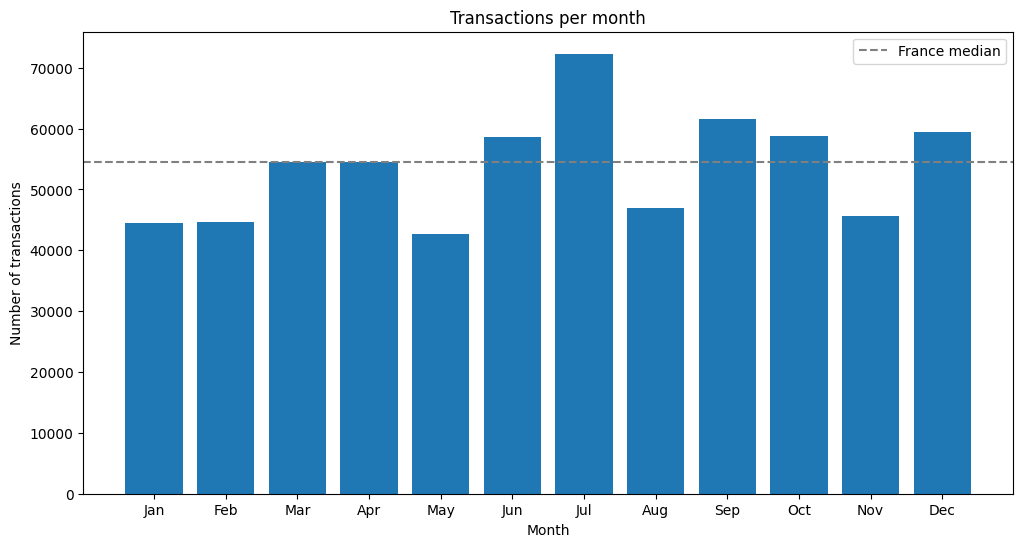

In [56]:
months = range(1, 13)
month_names = [calendar.month_abbr[m] for m in months]

plt.figure(figsize=(12, 6))

plt.bar(
    monthly_core_transactions.index,
    monthly_core_transactions.values
)

plt.axhline(np.median(monthly_core_transactions, axis=0), label="France median" ,color="grey", linestyle="dashed")

plt.title("Transactions per month")
plt.xlabel("Month")
plt.xticks(months, month_names)
plt.ylabel("Number of transactions")

plt.legend(loc="upper right")

plt.show()

In [57]:
monthly_core_prices = (
    df_core.groupby(df["Date mutation"].dt.month)["prix_m2"]
    .median()
)
print(monthly_prices)

Date mutation
1     2555.555556
2     2535.168659
3     2606.847375
4     2500.000000
5     2517.157275
6     2619.047619
7     2629.629630
8     2543.774485
9     2651.515152
10    2591.400183
11    2531.250000
12    2567.893443
Name: prix_m2, dtype: float64


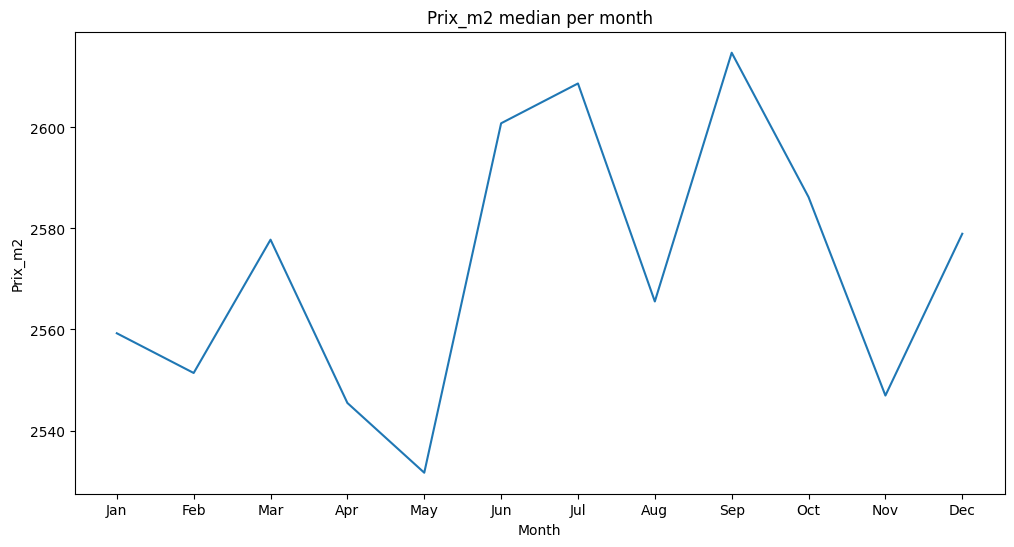

In [58]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_core_prices.index,
    monthly_core_prices.values
)

plt.title("Prix_m2 median per month")
plt.xlabel("Month")
plt.xticks(months, month_names)
plt.ylabel("Prix_m2")

plt.show()

### `Surface reelle bati` analysis

In [59]:
df_core["Surface reelle bati"].describe()

count    644137.000000
mean         82.869251
std          40.186941
min           1.000000
25%          56.000000
50%          78.000000
75%         102.000000
max         802.000000
Name: Surface reelle bati, dtype: float64

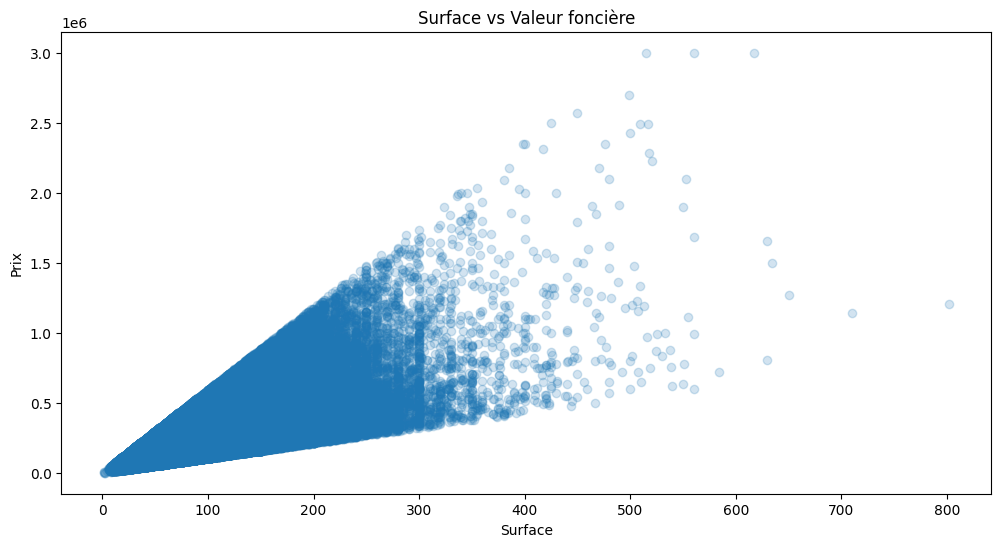

In [60]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_core["Surface reelle bati"],
    df_core["Valeur fonciere"],
    alpha=0.2
)

plt.title("Surface vs Valeur foncière")
plt.xlabel("Surface")
plt.ylabel("Prix")

plt.show()

### Correlations

In [61]:
numeric_cols = df_core[["Valeur fonciere", "Surface reelle bati", "Nombre pieces principales", "prix_m2"]]

print(numeric_cols.corr(method="spearman"))

                           Valeur fonciere  Surface reelle bati  \
Valeur fonciere                   1.000000             0.656426   
Surface reelle bati               0.656426             1.000000   
Nombre pieces principales         0.560893             0.848992   
prix_m2                           0.521605            -0.239854   

                           Nombre pieces principales   prix_m2  
Valeur fonciere                             0.560893  0.521605  
Surface reelle bati                         0.848992 -0.239854  
Nombre pieces principales                   1.000000 -0.216092  
prix_m2                                    -0.216092  1.000000  


|            |            Before            |            After             |
|------------|:----------------------------:|:----------------------------:|
| 1st Factor |          `prix_m2`           |    `Surface reelle bati`     |
| 2nd Factor |    `Surface reelle bati`     |          `prix_m2`           |
| 3rd Factor | `Nombre pieces principales`  | `Nombre pieces principales`  |

The number of parts influences the price well, however :
- not in a linear way
- rather progressive

Surface and price per square meter are both strongly associated with property value.

**Some remarks** :
- *Surface ↔ prix_m2* and *Nombre pieces ↔ prix_m2* : The larger the properties are, the more the price/m² tends to decrease
- The `Surface` is more important
- The `Nombre pieces principales` matters
- Large properties have a lower price/m²
- The **real estate market is non-linear**

Real estate variables are strongly related, but according to non-linear relationships. The built area appears as a major factor in land value, while the number of rooms also plays a significant role. Large properties, however, tend to have a lower price per square meter.

In [62]:
df_core.sort_values(
    by="Valeur fonciere",
    ascending=False
)[[
    "Commune",
    "Type local",
    "Valeur fonciere",
    "Surface reelle bati",
    "prix_m2"
]].head(20)

,Commune,Type local,Valeur fonciere,Surface reelle bati,prix_m2
670180,TALMONT-SAINT-HILAIRE,Maison,3004400.0,560.0,5365.000000
642167,SAINT TROPEZ,Maison,3000000.0,515.0,5825.242718
568787,MAXILLY-SUR-LEMAN,Maison,3000000.0,617.0,4862.236629
233762,BORDEAUX,Maison,2700005.0,499.0,5410.831663
661224,GORDES,Maison,2573000.0,450.0,5717.777778
658028,LE CASTELLET,Maison,2500000.0,425.0,5882.352941
562720,VETRAZ-MONTHOUX,Maison,2493081.0,509.0,4897.998035
616929,VESINET (LE),Maison,2493000.0,517.0,4822.050290
375339,ROCHEFORT-SUR-LOIRE,Maison,2431200.0,500.0,4862.400000
217615,TOULOUSE,Maison,2350000.0,476.0,4936.974790
